# Spatial Data, Support, and Distance

Companion notebook for [spatial_data_and_distance.md](../../notes/spatial_statistics/spatial_data_and_distance.md). We reproduce the chapter's key numbers: longitude distortion, great-circle distance, support and aggregation, the MAUP zoning effect, and network versus Euclidean distance.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
np.set_printoptions(precision=3, suppress=True)


## 1. One degree of longitude is not a fixed distance

One degree along a great circle is $2\pi R/360\approx111.2$ km, and one degree of longitude shrinks by $\cos\phi$ with latitude $\phi$.

one degree on a great circle: 111.19 km
latitude  0 deg -> 1 deg longitude =  111.2 km
latitude 30 deg -> 1 deg longitude =   96.3 km
latitude 45 deg -> 1 deg longitude =   78.6 km
latitude 60 deg -> 1 deg longitude =   55.6 km
latitude 80 deg -> 1 deg longitude =   19.3 km


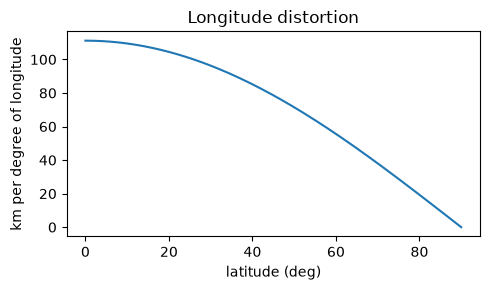

In [2]:
R = 6371.0
deg_km = 2*np.pi*R/360
lat = np.array([0, 30, 45, 60, 80])
print("one degree on a great circle: %.2f km" % deg_km)
for p, d in zip(lat, deg_km*np.cos(np.radians(lat))):
    print(f"latitude {p:2d} deg -> 1 deg longitude = {d:6.1f} km")

grid = np.linspace(0, 90, 181)
plt.figure(figsize=(5,3))
plt.plot(grid, deg_km*np.cos(np.radians(grid)))
plt.xlabel("latitude (deg)"); plt.ylabel("km per degree of longitude")
plt.title("Longitude distortion"); plt.tight_layout(); plt.show()

## 2. Great-circle (haversine) distance versus naive degree-space distance

Treating degrees as Cartesian units is wrong in both units and scale. Below, the same $1^\circ$ longitude difference is evaluated at three latitudes.

In [3]:
def haversine(lat1, lon1, lat2, lon2, R=6371.0):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dphi, dlam = p2-p1, np.radians(lon2-lon1)
    a = np.sin(dphi/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(dlam/2)**2
    return R*2*np.arctan2(np.sqrt(a), np.sqrt(1-a))

for phi in (0, 45, 60):
    print(f"lat {phi:2d}: naive = 1.000 'degrees', haversine = {haversine(phi,0,phi,1):6.2f} km")

# a long east-west trip: Berlin -> Warsaw
print("Berlin-Warsaw: %.0f km" % haversine(52.52,13.40,52.23,21.01))

lat  0: naive = 1.000 'degrees', haversine = 111.19 km
lat 45: naive = 1.000 'degrees', haversine =  78.63 km
lat 60: naive = 1.000 'degrees', haversine =  55.60 km
Berlin-Warsaw: 517 km


## 3. Support: averaging smooths variability

We simulate a spatially correlated 1D field of fine-scale values and average it over blocks of increasing size. The mean is preserved but the variance falls. This is the change-of-support effect (compare the chapter's eight-value example, variance $30\to29$).

In [4]:
vals = np.array([2,4,6,8,12,14,16,18.])
print("chapter example: var fine =", vals.var(), " var pair means =", vals.reshape(4,2).mean(1).var())

n = 1024
white = rng.normal(size=n+30)
field = np.convolve(white, np.ones(16)/16, mode="valid")[:n] + 0.5*rng.normal(size=n)
for b in (1, 4, 16, 64, 256):
    m = field.reshape(-1, b).mean(1)
    print(f"block size {b:3d}: n={m.size:4d}  mean={m.mean():6.3f}  var={m.var():.4f}")

chapter example: var fine = 30.0  var pair means = 29.0
block size   1: n=1024  mean=-0.071  var=0.3202
block size   4: n= 256  mean=-0.071  var=0.1195
block size  16: n=  64  mean=-0.071  var=0.0526
block size  64: n=  16  mean=-0.071  var=0.0184
block size 256: n=   4  mean=-0.071  var=0.0029


## 4. MAUP zoning effect

Four fine-scale cells have values $2,4,8,10$. Two zonings into two regions keep the overall mean but give very different regional contrasts.

In [5]:
x = np.array([2,4,8,10.])
zonings = {"(2,4),(8,10)": [[0,1],[2,3]], "(2,8),(4,10)": [[0,2],[1,3]]}
for name, z in zonings.items():
    means = np.array([x[g].mean() for g in z])
    print(f"{name:14s} regional means = {means}  between-region variance = {means.var():.2f}")

# regression slope depends on zoning: simulate x and y, aggregate in different zones
pts = 200
xs = rng.uniform(0, 10, pts); ys = 0.5*xs + rng.normal(0, 2, pts)
def slope(a, b): return np.polyfit(a, b, 1)[0]
print("point-level slope: %.3f" % slope(xs, ys))
order = np.argsort(xs)
z_sorted = np.array_split(order, 20)               # zones along x
z_random = np.array_split(rng.permutation(pts), 20)  # arbitrary zones
for name, z in (("x-sorted zones", z_sorted), ("random zones", z_random)):
    a = np.array([xs[g].mean() for g in z]); b = np.array([ys[g].mean() for g in z])
    print(f"{name:15s} slope = {slope(a,b):6.3f}  corr = {np.corrcoef(a,b)[0,1]:6.3f}")

(2,4),(8,10)   regional means = [3. 9.]  between-region variance = 9.00
(2,8),(4,10)   regional means = [5. 7.]  between-region variance = 1.00
point-level slope: 0.483
x-sorted zones  slope =  0.483  corr =  0.910
random zones    slope =  0.504  corr =  0.564


## 5. Euclidean versus network distance, and area weighting

The chapter's example: points $A=(0,0)$ and $B=(3,4)$ are 5 apart in a straight line but 9 apart if travel must go via $C$. Then a district overlapping three raster cells is averaged by area weights.

In [6]:
A, B = np.array([0,0.]), np.array([3,4.])
print("Euclidean:", np.hypot(*(B-A)), " via C (4 + 5):", 4+5)

# area-weighted aggregation
cells = np.array([4, 8, 10.]); w = np.array([0.2, 0.5, 0.3])
print("area weighted:", w @ cells, " unweighted:", cells.mean().round(3))

# effect of the distance rule on neighbors within 5 km
pos = np.array([[0,0],[3,4],[1,1],[6,0.]])
D_euc = np.linalg.norm(pos[:,None]-pos[None], axis=2)
D_net = D_euc.copy(); D_net[0,1] = D_net[1,0] = 9   # A-B must detour
print("neighbors within 5 (Euclid):\n", ((D_euc>0)&(D_euc<=5)).astype(int))
print("neighbors within 5 (network):\n", ((D_net>0)&(D_net<=5)).astype(int))

Euclidean: 5.0  via C (4 + 5): 9
area weighted: 7.8  unweighted: 7.333
neighbors within 5 (Euclid):
 [[0 1 1 0]
 [1 0 1 1]
 [1 1 0 0]
 [0 1 0 0]]
neighbors within 5 (network):
 [[0 0 1 0]
 [0 0 1 1]
 [1 1 0 0]
 [0 1 0 0]]


## Takeaways

- Degrees are angular; use a projected CRS or great-circle distance before computing distances.
- Averaging over larger support preserves the mean but shrinks variance; the amount depends on spatial dependence.
- Regional summaries and regression slopes depend on the zoning (MAUP), so state the unit of analysis.
- The neighbor graph changes when the distance definition changes, which flows into Moran's $I$ and spatial models.